# Phantom Fairness: auditing fairness against automatically extracted labels

### Part 2 of 4 - Linear heads, subgroup gaps on NLP versus reference-standard labels, and the anatomy of the label noise

This notebook reproduces the original Part 2 analyses on the same cohort and the same cached embeddings, and changes how uncertainty is computed:

| Change | Reviewer comment addressed |
|---|---|
| Every interval and every paired NLP-versus-reference comparison now resamples **patients** rather than images (cluster bootstrap). Image-level intervals are kept beside them, and the original-submission table is compared row by row, so any change in direction or magnitude is visible. | R4.1 |
| Subgroup AUROCs carry patient-level bootstrap intervals in addition to the DeLong (image-level) intervals. | R4.1 |
| Cohort flow, clustering of images within patients, representativeness of the evaluation set against the rest of ChestX-ray14 (standardised mean differences), and an audit of the adjudicated label file (`Set Id`, raw label values, metadata agreement). | R4.4 |
| A fourth backbone, DenseNet-121 trained only on CheXpert, which never saw NIH images, NIH NLP labels or the adjudicated labels. | R4.3 |
| Fracture analysed with that unexposed backbone and with thresholds chosen on one half of the patients and tested on the other (cross-fitted), so no threshold is chosen on the labels it is tested against. | R4.3, R1.3 |
| Head-training and inference times are recorded for the compute-cost table (Part 4). | R1.4 |

Terminology: the radiologist-adjudicated labels are called the **reference standard** throughout.

Run Part 1 at least once first (it builds the image index and the label files). Shared code lives in `phantom_core.py`, which must sit next to the notebooks.

---
## 0. Setup

In [1]:
import sys, os, json, time
from pathlib import Path
# phantom_core.py must sit in the same folder as the notebooks.
for _p in (Path.cwd(), Path.cwd() / "notebooks"):
    if (_p / "phantom_core.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import phantom_core as pc
import os
os.environ["PF_PROJECT_DIR"] = r"C:\Users\kruta\Downloads\phantom_fairness"

CFG = pc.Config()
CFG.project_dir = r"C:\Users\kruta\Downloads\phantom_fairness"   # Part 1 output folder
CFG.ensure_dirs()
print("Using:", CFG.out)
CFG.chex_full_pipeline = False
# Manuscript-run settings are the defaults in phantom_core.Config.
# Manuscript-run settings are the defaults in phantom_core.Config.
# Set the environment variable PF_QUICK=1 for a fast dry run (small resample counts).
if os.environ.get("PF_QUICK"):
    CFG.n_bootstrap, CFG.n_wcr, CFG.n_inject_mc = 200, 100, 30
    CFG.n_inject_boot, CFG.n_inject_boot_mc, CFG.n_crossfit_splits = 30, 5, 20
VERSIONS = pc.setup_runtime(CFG)
TIMES = pc.Timings(CFG, "part2")
log = pc.log
ARCHIVE = pc.archive_v1_outputs(CFG)
print("Project folder:", CFG.out)
print("Original-submission tables archived at:", ARCHIVE)
print(json.dumps(VERSIONS, indent=2))

Using: C:\Users\kruta\Downloads\phantom_fairness
Project folder: C:\Users\kruta\Downloads\phantom_fairness
Original-submission tables archived at: C:\Users\kruta\Downloads\phantom_fairness\tables\v1_original
{
  "python": "3.11.15",
  "numpy": "2.4.4",
  "pandas": "3.0.3",
  "matplotlib": "3.11.0",
  "platform": "Windows-10-10.0.26300-SP0",
  "sklearn": "1.9.0",
  "scipy": "1.17.1",
  "statsmodels": "0.14.6",
  "torch": "2.12.1+cpu",
  "torchvision": "0.27.1+cpu",
  "torchxrayvision": "1.4.0",
  "open_clip": "3.3.0"
}


---
## 1. Cohort, selection of the evaluation set, and representativeness

The cohort is rebuilt with exactly the original code and seed. The cell checks the SHA-256 hash of each split's ordered image list against the cached embedding manifests from the first run and stops if anything differs, so the numbers below are guaranteed to come from the same images.

**How the evaluation images were selected (for the Methods).** The evaluation set is every image that carries a radiologist-adjudicated label in the file distributed with TorchXRayVision (Majkowska et al., 2020). For ChestX-ray14, Majkowska et al. drew these images at random (the dataset is already enriched for abnormal findings) from their validation split and from the original NIH test split, excluding images with technical problems. Each image was read independently by three radiologists; disagreements were resolved by up to five rounds of anonymous asynchronous discussion. The released labels are YES or NO only (no uncertain category), which the audit below confirms. Because the evaluation set is held out at patient level, all other images of those patients are excluded from training and validation.

In [2]:
with TIMES.track("load_masters_and_cohort"):
    nih_master, padchest_master, ADJ_AUDIT = pc.load_masters(CFG)
    train_df, val_df, test_df, eval_clean = pc.build_cohort(CFG, nih_master)
FRAMES = {"train": train_df, "val": val_df, "evalclean": eval_clean}
NLP_FINDINGS = pc.nlp_findings(CFG)          # Fracture has no NLP label and is handled separately
AXES = pc.SUBGROUP_AXES
CHECK = pc.check_cohort_against_cache(CFG, FRAMES)
if len(CHECK):
    display(CHECK)
    bad = CHECK[~CHECK["match"]]
    if len(bad) and not CFG.allow_reextract:
        raise RuntimeError("The rebuilt cohort does not match the cached embeddings listed above. "
                           "Do not continue: the numbers would not correspond to the original run.")
print(f"train {len(train_df)} | val {len(val_df)} | held-out {len(test_df)} | evaluation {len(eval_clean)} images, "
      f"{eval_clean['patient_id'].nunique()} patients")

17:58:53 [INFO] Loaded master_nih_v2 from cache: 112120 rows


,split,manifest,n,match
0,train,train__clip_vitb32__manifest.json,20000,True
1,train,train__resnet50_imagenet__manifest.json,20000,True
2,train,train__xrv_densenet121__manifest.json,20000,True
3,val,val__clip_vitb32__manifest.json,12930,True
4,val,val__resnet50_imagenet__manifest.json,12930,True
5,val,val__xrv_densenet121__manifest.json,12930,True
6,evalclean,evalclean__clip_vitb32__manifest.json,4376,True
7,evalclean,evalclean__resnet50_imagenet__manifest.json,4376,True
8,evalclean,evalclean__xrv_densenet121__manifest.json,4376,True


train 20000 | val 12930 | held-out 26921 | evaluation 4376 images, 1695 patients


In [3]:
# Cohort flow (STARD/TRIPOD-style counts)
m = nih_master
adj = m[m["has_adjudicated"]]
pool = m[~m["patient_id"].isin(set(test_df["patient_id"]))]
train_cands = pool[~pool["patient_id"].isin(set(val_df["patient_id"]))]
EVAL_ROWS = pc.filter_eval_groups(eval_clean.copy(), AXES, CFG.min_group_n)
flow = [("NIH ChestX-ray14 images with metadata", m),
        ("Images with radiologist-adjudicated labels", adj)]
for sid, d in adj.groupby("gmeta_set_id"):
    flow.append((f"   of which Google split '{sid}'", d))
flow += [("Held out: all images of patients with any adjudicated image", test_df),
         ("   Evaluation set: adjudicated images of held-out patients", eval_clean),
         ("   Entering subgroup analyses (subgroups with >= 20 images)", EVAL_ROWS),
         ("Development pool: patients without any adjudicated image", pool),
         ("   Validation: random 15% of pool patients, all their images", val_df),
         ("   Training candidates: remaining pool patients", train_cands),
         ("   Training sample: random 20,000 images of the candidates", train_df)]
FLOW = pd.DataFrame([{"step": s, "images": len(d), "patients": int(d["patient_id"].nunique())} for s, d in flow])
FLOW.to_csv(CFG.tab_dir / "table_cohort_flow.csv", index=False)
display(FLOW)

# Clustering of images within patients in the evaluation set (motivates the patient-level bootstrap)
ipp = eval_clean.groupby("patient_id").size()
clus = [{"set": "all evaluation images", "images": len(eval_clean), "patients": len(ipp),
         "images_per_patient_mean": ipp.mean(), "median": ipp.median(), "max": ipp.max(),
         "pct_patients_with_>1_image": 100 * (ipp > 1).mean(),
         "pct_images_from_patients_with_>1_image": 100 * ipp[ipp > 1].sum() / ipp.sum()}]
for f in list(NLP_FINDINGS) + ["Fracture"]:
    pos = eval_clean[eval_clean["adj_" + f] == 1]
    pp = pos.groupby("patient_id").size()
    clus.append({"set": f"reference-standard positives: {f}", "images": len(pos), "patients": len(pp),
                 "images_per_patient_mean": pp.mean(), "median": pp.median(), "max": pp.max(),
                 "pct_patients_with_>1_image": 100 * (pp > 1).mean(),
                 "pct_images_from_patients_with_>1_image": 100 * pp[pp > 1].sum() / max(1, pp.sum())})
CLUSTER = pd.DataFrame(clus)
CLUSTER.to_csv(CFG.tab_dir / "table_eval_clustering.csv", index=False)
display(CLUSTER.round(2))

,step,images,patients
0,NIH ChestX-ray14 images with metadata,112120,30805
1,Images with radiologist-adjudicated labels,4376,1695
2,of which Google split 'test',1962,860
3,of which Google split 'val',2414,835
4,Held out: all images of patients with any adju...,26921,1695
5,Evaluation set: adjudicated images of held-...,4376,1695
6,Entering subgroup analyses (subgroups with ...,4375,1694
7,Development pool: patients without any adjudic...,85199,29110
8,"Validation: random 15% of pool patients, al...",12930,4366
9,Training candidates: remaining pool patients,72269,24744


,set,images,patients,images_per_patient_mean,median,max,pct_patients_with_>1_image,pct_images_from_patients_with_>1_image
0,all evaluation images,4376,1695,2.58,1.0,56,45.90,79.04
1,reference-standard positives: Airspace opacity,2166,820,2.64,1.0,47,47.93,80.29
2,reference-standard positives: Pneumothorax,238,154,1.55,1.0,6,31.17,55.46
3,reference-standard positives: Nodule or mass,605,346,1.75,1.0,36,32.37,61.32
4,reference-standard positives: Fracture,186,106,1.75,1.0,44,20.75,54.84


In [4]:
# Representativeness: evaluation set versus the development pool and the full dataset
def cohort_profile(d, name):
    pats = d.groupby("patient_id").size()
    rec = {"cohort": name, "images": len(d), "patients": int(d["patient_id"].nunique()),
           "images_per_patient": pats.mean(), "age_mean": d["age"].mean(), "age_sd": d["age"].std(),
           "female_pct": 100 * (d["sex"] == "F").mean(), "AP_pct": 100 * (d["view"] == "AP").mean(),
           "follow_up_median": d["follow_up"].median(), "No_Finding_pct": 100 * d["nih_No_Finding"].mean()}
    for f in NLP_FINDINGS:
        rec[f"NLP {f} pct"] = 100 * d["nlp_" + f].mean()
    for f in pc.NIH14:
        rec[f"NIH {f} pct"] = 100 * d["nih_" + f].mean()
    return rec

PROFILE = pd.DataFrame([cohort_profile(m, "All ChestX-ray14"), cohort_profile(eval_clean, "Evaluation set"),
                        cohort_profile(pool, "Development pool"), cohort_profile(train_df, "Training sample"),
                        cohort_profile(val_df, "Validation set")]).set_index("cohort").T
smd_rows = [("age", "age", False), ("female", None, True), ("AP projection", None, True),
            ("follow-up number", "follow_up", False), ("No Finding", "nih_No_Finding", True)] + \
           [(f"NLP {f}", "nlp_" + f, True) for f in NLP_FINDINGS] + [(f"NIH {f}", "nih_" + f, True) for f in pc.NIH14]
def _col(d, name, col):
    if name == "female": return (d["sex"] == "F").astype(float)
    if name == "AP projection": return (d["view"] == "AP").astype(float)
    return d[col]
SMD = pd.DataFrame([{"variable": n, "SMD evaluation vs development pool": pc.smd(_col(eval_clean, n, c), _col(pool, n, c), b),
                     "SMD evaluation vs all ChestX-ray14": pc.smd(_col(eval_clean, n, c), _col(m, n, c), b)}
                    for n, c, b in smd_rows])
PROFILE.to_csv(CFG.tab_dir / "table_representativeness_profile.csv")
SMD.to_csv(CFG.tab_dir / "table_representativeness_smd.csv", index=False)
display(PROFILE.round(2)); display(SMD.round(3))
print("Variables with |SMD| > 0.1 (evaluation vs development pool):",
      SMD.loc[SMD.iloc[:, 1].abs() > 0.1, "variable"].tolist())

cohort,All ChestX-ray14,Evaluation set,Development pool,Training sample,Validation set
images,112120.00,4376.00,85199.00,20000.00,12930.00
patients,30805.00,1695.00,29110.00,10998.00,4366.00
images_per_patient,3.64,2.58,2.93,1.82,2.96
age_mean,46.87,46.49,46.91,46.87,47.10
age_sd,16.60,16.40,16.68,16.79,16.25
female_pct,43.51,40.33,44.12,44.35,43.94
AP_pct,39.97,74.13,33.26,33.04,34.20
follow_up_median,3.00,6.00,2.00,2.00,2.00
No_Finding_pct,53.84,47.76,58.53,58.18,59.19
NLP Airspace opacity pct,20.82,26.53,18.01,18.30,17.11


,variable,SMD evaluation vs development pool,SMD evaluation vs all ChestX-ray14
0,age,-0.025,-0.023
1,female,-0.077,-0.064
2,AP projection,0.899,0.735
3,follow-up number,0.583,0.275
4,No Finding,-0.217,-0.122
5,NLP Airspace opacity,0.206,0.135
6,NLP Pneumothorax,0.110,0.032
7,NLP Nodule or mass,0.036,0.013
8,NIH Atelectasis,0.075,0.048
9,NIH Cardiomegaly,0.060,0.033


Variables with |SMD| > 0.1 (evaluation vs development pool): ['AP projection', 'follow-up number', 'No Finding', 'NLP Airspace opacity', 'NLP Pneumothorax', 'NIH Effusion', 'NIH Infiltration', 'NIH Pneumothorax', 'NIH Consolidation', 'NIH Edema']


In [5]:
# Audit of the adjudicated label file
checks = []
if len(ADJ_AUDIT):
    for _, r in ADJ_AUDIT.iterrows():
        checks.append({"check": f"raw values in '{r['source_column']}'", "result": r["raw_values"]})
ev = eval_clean
checks.append({"check": "images in adjudicated file joined to NIH index", "result": int(nih_master["has_adjudicated"].sum())})
checks.append({"check": "Google split counts (Set Id)", "result": json.dumps(ev["gmeta_set_id"].value_counts().to_dict())})
checks.append({"check": "note", "result": "Google's release notes report 2,412 validation and 1,962 test images (4,374); "
               "the TorchXRayVision copy used here has the counts shown above."})
def _agree(a, b):
    return round(100 * float((a.astype(str).str.strip().str.upper() == b.astype(str).str.strip().str.upper()).mean()), 2)
if "gmeta_finding_labels" in ev.columns:
    checks.append({"check": "% images whose NIH 'Finding Labels' string is identical in the adjudicated file",
                   "result": _agree(ev["gmeta_finding_labels"], ev["nih_finding_labels"])})
if "gmeta_patient_id" in ev.columns:
    checks.append({"check": "% patient ID agreement", "result": _agree(pd.to_numeric(ev["gmeta_patient_id"], errors="coerce").astype("Int64"),
                                                                     pd.to_numeric(ev["patient_id"], errors="coerce").astype("Int64"))})
if "gmeta_sex" in ev.columns:
    checks.append({"check": "% sex agreement", "result": _agree(ev["gmeta_sex"].str[0], ev["sex"])})
if "gmeta_view" in ev.columns:
    checks.append({"check": "% projection agreement", "result": _agree(ev["gmeta_view"], ev["view"])})
for f in pc.NIH_TO_CANON_TIGHT:
    checks.append({"check": f"mapping: {f}", "result": " | ".join(pc.NIH_TO_CANON_TIGHT[f]) or "no NLP label (all negative)"})
FILECHK = pd.DataFrame(checks)
FILECHK.to_csv(CFG.tab_dir / "table_adjudicated_file_checks.csv", index=False)
pd.set_option("display.max_colwidth", 200)
display(FILECHK)

,check,result
0,raw values in 'Airspace opacity',"{""NO"": 2210, ""YES"": 2166}"
1,raw values in 'Pneumothorax',"{""NO"": 4138, ""YES"": 238}"
2,raw values in 'Nodule or mass',"{""NO"": 3771, ""YES"": 605}"
3,raw values in 'Fracture',"{""NO"": 4190, ""YES"": 186}"
4,images in adjudicated file joined to NIH index,4376
5,Google split counts (Set Id),"{""val"": 2414, ""test"": 1962}"
6,note,"Google's release notes report 2,412 validation and 1,962 test images (4,374); the TorchXRayVision copy used here has the counts shown above."
7,% images whose NIH 'Finding Labels' string is identical in the adjudicated file,100.0
8,% patient ID agreement,100.0
9,% sex agreement,100.0


---
## 2. Frozen embeddings (cached)

The primary backbone's embeddings are loaded from the cache written in the first run. Nothing is re-extracted unless the cohort changed, in which case the cell above has already stopped.

In [6]:
EMB, MODELS, EVALS, HEAD_TIMES = {}, {}, {}, {}
P = CFG.primary_backbone

# Stop before a multi-hour extraction if the cache is not where we expect it
print("Embedding folder:", CFG.emb_dir)
missing = [t for t in ("train", "val", "evalclean")
           if not (CFG.emb_dir / f"{t}__{P}.npy").exists()]
print("Missing cached files for:", missing or "none, cache will be loaded")
if missing:
    raise SystemExit(
        f"No cache for {missing} in {CFG.emb_dir}. Set PF_PROJECT_DIR to your Part 1 output "
        "folder (the one that contains 'embeddings') and restart the kernel, "
        "or run the extraction deliberately by deleting this check.")

with TIMES.track(f"embeddings_{P}"):
    EMB[P] = pc.embed_frames(CFG, P, FRAMES)
print("Primary embeddings:", {k: (None if v[0] is None else v[0].shape) for k, v in EMB[P].items()})

Embedding folder: C:\Users\kruta\Downloads\phantom_fairness\embeddings
Missing cached files for: none, cache will be loaded
Primary embeddings: {'train': (20000, 1024), 'val': (12930, 1024), 'evalclean': (4376, 1024)}


---
## 3. Linear heads trained on the NLP labels

Unchanged: one logistic regression per finding (C = 1.0, class-balanced weights, up to 2,000 iterations) on standardised embeddings, trained on NLP labels; the operating threshold maximises Youden's index on the validation split against NLP labels. The reference standard is used only for evaluation. Part 4 adds a grid search over C on the validation split and a patient-grouped five-fold resampling of the development pool (R1.5, R1.7).

In [7]:
HEAD_TIMES[P] = {}
MODELS[P] = pc.train_heads(EMB[P], NLP_FINDINGS, C=CFG.head_C, timings=HEAD_TIMES[P])
print("Thresholds (Youden, NLP validation labels):", {k: round(v, 3) for k, v in MODELS[P]["thresholds"].items()})
pc.write_json(CFG.prov_dir / f"head_timings_{P}.json", HEAD_TIMES[P])

Thresholds (Youden, NLP validation labels): {'Airspace opacity': 0.474, 'Pneumothorax': 0.084, 'Nodule or mass': 0.537}


---
## 4. Statistical methods used from here on

* **Gaps.** Largest minus smallest subgroup value of the true-positive rate (TPR) at the operating threshold, and of the AUROC.
* **Regime difference.** Gap on reference-standard labels minus gap on NLP labels for the same images; positive means an NLP-label audit understates the disparity.
* **Patient-level bootstrap (primary).** Each replicate draws the 1,695 evaluation patients with replacement and keeps all images of every drawn patient; the NLP and reference-standard gaps are computed on the same replicate, so the comparison stays paired. Percentile 95% intervals; two-sided p as twice the smaller tail of the replicate distribution of the difference; Benjamini-Hochberg across the 24 comparisons. 5,000 replicates.
* **Image-level bootstrap (comparison only).** The same with each image as its own cluster, which is what the original submission did.
* **Subgroup AUROC intervals.** DeLong (image level) and patient-level bootstrap.
* **A caution on gap intervals.** A gap (largest minus smallest subgroup value) is biased upwards under resampling, so when the true gap is near zero its percentile interval can lie entirely above the point estimate. The regime difference, a difference of two such gaps on the same replicate, is much less affected. Error bars in the figure are clipped at the point estimate in that case.

The code is vectorised (resampling weights rather than copied data frames) and was checked against the original pandas implementation: with unit weights the gaps are identical to machine precision.

---
## 5. Evaluation frame

In [8]:
EVALS[P] = pc.filter_eval_groups(pc.build_eval_scores(MODELS[P], P), AXES, CFG.min_group_n)
EVAL = EVALS[P]
print("Evaluation frame:", len(EVAL), "images,", EVAL["patient_id"].nunique(), "patients")
print({ax: EVAL[ax].value_counts().to_dict() for ax in AXES})

Evaluation frame: 4375 images, 1694 patients
{'sex': {'M': 2610, 'F': 1765}, 'age_band': {'40-60': 1917, '<40': 1435, '>60': 1023}, 'view': {'AP': 3244, 'PA': 1131}, 'elderly_women': {'other': 4014, 'F>60': 361}}


---
## 6. Subgroup gaps on NLP versus reference-standard labels (same images), patient-level inference

This family is descriptive (limited power at the adjudicated sample size). The table reports both the patient-level and the image-level intervals, and the next cell compares each row with the original submission.

In [9]:
with TIMES.track("regime_difference_table_primary"):
    HEAD = pc.regime_difference_table(EVAL, NLP_FINDINGS, AXES, MODELS[P]["thresholds"], n_boot=CFG.n_bootstrap,
                                      seed=CFG.random_seed, chunk=CFG.boot_chunk)
HEAD.to_csv(CFG.tab_dir / "table2_headline_phantom_fairness.csv", index=False)
show = HEAD[["finding", "axis", "metric", "gap_nlp", "gap_ref", "regime_diff", "diff_lo_patient", "diff_hi_patient",
             "p_two_patient", "p_bh_patient", "diff_lo_image", "diff_hi_image", "ci_width_ratio_patient_vs_image"]]
display(show.round(3))
pos = HEAD["regime_diff"] > 0
print(f"Reference-standard gap larger in {int(pos.sum())} of {len(HEAD)} comparisons; median difference "
      f"{HEAD['regime_diff'].median():.3f}")
for met in ("tpr", "auroc"):
    h = HEAD[HEAD["metric"] == met]
    print(f"  {met}: larger in {int((h['regime_diff'] > 0).sum())} of {len(h)}, median {h['regime_diff'].median():.3f}")
print(f"Patient-level intervals excluding zero: {int(((HEAD['diff_lo_patient'] > 0) | (HEAD['diff_hi_patient'] < 0)).sum())}; "
      f"unadjusted p < 0.05: {int((HEAD['p_two_patient'] < 0.05).sum())}; BH-adjusted p < 0.05: {int((HEAD['p_bh_patient'] < 0.05).sum())} "
      f"(minimum adjusted p {HEAD['p_bh_patient'].min():.3f})")
print(f"Median ratio of patient-level to image-level interval width: {HEAD['ci_width_ratio_patient_vs_image'].median():.2f}")

,finding,axis,metric,gap_nlp,gap_ref,regime_diff,diff_lo_patient,diff_hi_patient,p_two_patient,p_bh_patient,diff_lo_image,diff_hi_image,ci_width_ratio_patient_vs_image
0,Airspace opacity,sex,tpr,0.020,0.010,-0.010,-0.052,0.032,0.745,0.991,-0.051,0.025,1.118
1,Airspace opacity,sex,auroc,0.001,0.030,0.029,-0.027,0.054,0.462,0.991,-0.019,0.047,1.217
2,Airspace opacity,age_band,tpr,0.034,0.074,0.040,-0.055,0.100,0.521,0.991,-0.043,0.090,1.166
3,Airspace opacity,age_band,auroc,0.025,0.039,0.014,-0.051,0.064,0.805,0.991,-0.043,0.053,1.202
4,Airspace opacity,view,tpr,0.236,0.235,-0.001,-0.081,0.075,0.959,0.991,-0.078,0.077,1.007
5,Airspace opacity,view,auroc,0.107,0.174,0.067,0.005,0.126,0.032,0.778,0.013,0.122,1.100
6,Airspace opacity,elderly_women,tpr,0.053,0.014,-0.039,-0.116,0.066,0.566,0.991,-0.115,0.059,1.044
7,Airspace opacity,elderly_women,auroc,0.061,0.001,-0.061,-0.102,0.033,0.264,0.991,-0.104,0.020,1.089
8,Pneumothorax,sex,tpr,0.122,0.124,0.002,-0.120,0.125,0.991,0.991,-0.110,0.122,1.058
9,Pneumothorax,sex,auroc,0.038,0.068,0.030,-0.048,0.096,0.532,0.991,-0.046,0.097,1.007


Reference-standard gap larger in 16 of 24 comparisons; median difference 0.021
  tpr: larger in 6 of 12, median 0.001
  auroc: larger in 10 of 12, median 0.029
Patient-level intervals excluding zero: 1; unadjusted p < 0.05: 1; BH-adjusted p < 0.05: 0 (minimum adjusted p 0.778)
Median ratio of patient-level to image-level interval width: 1.05


In [10]:
# Row-by-row comparison with the original submission (R4.1: did direction or magnitude change?)
v1p = CFG.tab_dir / "v1_original" / "table2_headline_phantom_fairness.csv"
if v1p.exists():
    v1 = pd.read_csv(v1p)
    cmp = HEAD.merge(v1[["finding", "axis", "metric", "regime_diff", "diff_lo", "diff_hi", "p_bh"]]
                     .rename(columns={"regime_diff": "v1_regime_diff", "diff_lo": "v1_lo_image_stratified",
                                      "diff_hi": "v1_hi_image_stratified", "p_bh": "v1_p_bh"}),
                     on=["finding", "axis", "metric"], how="left")
    cmp["point_estimate_unchanged"] = np.isclose(cmp["regime_diff"], cmp["v1_regime_diff"], atol=1e-9)
    cmp["direction_unchanged"] = np.sign(cmp["regime_diff"]) == np.sign(cmp["v1_regime_diff"])
    cmp = cmp[["finding", "axis", "metric", "v1_regime_diff", "regime_diff", "point_estimate_unchanged",
               "v1_lo_image_stratified", "v1_hi_image_stratified", "diff_lo_patient", "diff_hi_patient", "v1_p_bh",
               "p_bh_patient"]]
    cmp.to_csv(CFG.tab_dir / "table2_v1_vs_v2_comparison.csv", index=False)
    display(cmp.round(3))
    print("Point estimates identical to the submission:", bool(cmp["point_estimate_unchanged"].all()))
else:
    print("No archived original table found; comparison skipped.")

,finding,axis,metric,v1_regime_diff,regime_diff,point_estimate_unchanged,v1_lo_image_stratified,v1_hi_image_stratified,diff_lo_patient,diff_hi_patient,v1_p_bh,p_bh_patient
0,Airspace opacity,sex,tpr,-0.010,-0.010,True,-0.051,0.025,-0.052,0.032,0.983,0.991
1,Airspace opacity,sex,auroc,0.029,0.029,True,-0.019,0.047,-0.027,0.054,0.983,0.991
2,Airspace opacity,age_band,tpr,0.040,0.040,True,-0.043,0.090,-0.055,0.100,0.983,0.991
3,Airspace opacity,age_band,auroc,0.014,0.014,True,-0.043,0.053,-0.051,0.064,0.992,0.991
4,Airspace opacity,view,tpr,-0.001,-0.001,True,-0.078,0.077,-0.081,0.075,0.992,0.991
5,Airspace opacity,view,auroc,0.067,0.067,True,0.013,0.122,0.005,0.126,0.432,0.778
6,Airspace opacity,elderly_women,tpr,-0.039,-0.039,True,-0.115,0.059,-0.116,0.066,0.983,0.991
7,Airspace opacity,elderly_women,auroc,-0.061,-0.061,True,-0.104,0.020,-0.102,0.033,0.983,0.991
8,Pneumothorax,sex,tpr,0.002,0.002,True,-0.110,0.122,-0.120,0.125,0.992,0.991
9,Pneumothorax,sex,auroc,0.030,0.030,True,-0.046,0.097,-0.048,0.096,0.983,0.991


Point estimates identical to the submission: True


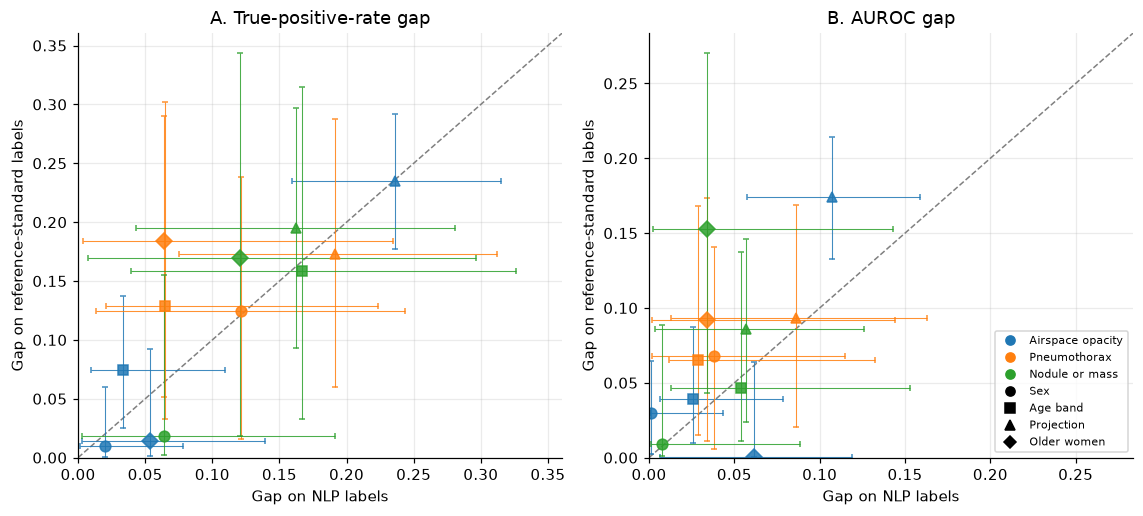

In [11]:
# Figure 3 (revised): NLP gap versus reference-standard gap with patient-level 95% intervals
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.8))
markers = {"sex": "o", "age_band": "s", "view": "^", "elderly_women": "D"}
colours = dict(zip(NLP_FINDINGS, ["C0", "C1", "C2"]))
for a, met, ttl in zip(axs, ["tpr", "auroc"], ["A. True-positive-rate gap", "B. AUROC gap"]):
    d = HEAD[HEAD["metric"] == met]
    mx = float(np.nanmax([d["nlp_hi_patient"].max(), d["ref_hi_patient"].max(), 0.1])) * 1.05
    a.plot([0, mx], [0, mx], ls="--", c="grey", lw=1)
    for _, r in d.iterrows():
        a.errorbar(r["gap_nlp"], r["gap_ref"],
                   xerr=[[max(0, r["gap_nlp"] - r["nlp_lo_patient"])], [max(0, r["nlp_hi_patient"] - r["gap_nlp"])]],
                   yerr=[[max(0, r["gap_ref"] - r["ref_lo_patient"])], [max(0, r["ref_hi_patient"] - r["gap_ref"])]],
                   fmt=markers[r["axis"]], color=colours[r["finding"]], ms=7, alpha=0.85, elinewidth=0.7, capsize=2)
    a.set_xlim(0, mx); a.set_ylim(0, mx); a.set_title(ttl)
    a.set_xlabel("Gap on NLP labels"); a.set_ylabel("Gap on reference-standard labels")
from matplotlib.lines import Line2D
h = [Line2D([], [], color=c, marker="o", ls="", label=f) for f, c in colours.items()] + \
    [Line2D([], [], color="k", marker=mk, ls="", label=pc.AXIS_LABELS[ax]) for ax, mk in markers.items()]
axs[1].legend(handles=h, fontsize=7, loc="lower right")
plt.savefig(CFG.fig_dir / "fig4_phantom_scatter.png", bbox_inches="tight"); plt.show()

---
## 7. Group-dependent label noise

Flip rates of the NLP labels against the reference standard, by subgroup: ε⁺ = P(NLP = 0 | reference = 1) and ε⁻ = P(NLP = 1 | reference = 0), with McNemar tests (unchanged) and, new, patient-level bootstrap intervals for ε⁺. The Wang, Liu and Levy (2021) class-conditional prediction of the noisy TPR is kept as a diagnostic: a large residual indicates that the noise is not class-conditional.

In [12]:
def noisy_from_clean(tpr, fpr, ep, em):
    return (1 - ep) * tpr + em * fpr, ep * tpr + (1 - em) * fpr

def noise_table(ev, axes=AXES):
    rows = []
    for f in NLP_FINDINGS:
        nlp, ad, sc = "nlp_" + f, "adj_" + f, "score_" + f
        thr = MODELS[P]["thresholds"].get(f, 0.5)
        sub = ev[ev[ad].notna()].reset_index(drop=True)
        codes, nc = pc.encode_clusters(sub["patient_id"].values)
        ya_all = sub[ad].astype(int).values; yn_all = sub[nlp].astype(int).values
        for ax in axes:
            for g in sorted(sub[ax].astype(str).unique()):
                msk = (sub[ax].astype(str) == g).values
                ya, yn, p = ya_all[msk], yn_all[msk], sub[sc].values[msk]
                yhat = (p >= thr).astype(int); pos, neg = ya == 1, ya == 0
                eps_p = float((yn[pos] == 0).mean()) if pos.sum() else np.nan
                eps_m = float((yn[neg] == 1).mean()) if neg.sum() else np.nan
                stat, pmc, b, c = pc.mcnemar(yn, ya)
                ctpr, cfpr = pc.tpr_fpr(ya, yhat); ntpr, nfpr = pc.tpr_fpr(yn, yhat)
                ptpr = noisy_from_clean(ctpr, cfpr, eps_p, eps_m)[0] if not np.isnan(eps_p + eps_m + ctpr + cfpr) else np.nan
                posv = (msk & (ya_all == 1)).astype(float); fnv = (msk & (ya_all == 1) & (yn_all == 0)).astype(float)
                R = []
                with np.errstate(all="ignore"):
                    for W in pc.iter_boot_weights(codes, nc, CFG.n_bootstrap, CFG.random_seed, CFG.boot_chunk):
                        R.append((W @ fnv) / (W @ posv))
                R = np.concatenate(R)
                rows.append({"finding": f, "axis": ax, "group": g, "n": int(msk.sum()), "ref_pos": int(pos.sum()),
                             "eps_plus_FN": eps_p, "eps_plus_lo_patient": np.nanpercentile(R, 2.5) if np.isfinite(R).any() else np.nan,
                             "eps_plus_hi_patient": np.nanpercentile(R, 97.5) if np.isfinite(R).any() else np.nan,
                             "eps_minus_FP": eps_m, "mcnemar_p": pmc, "nlp_missed_pos": int((pos & (yn == 0)).sum()),
                             "clean_tpr": ctpr, "noisy_tpr_obs": ntpr, "noisy_tpr_pred": ptpr,
                             "lemma1_resid_tpr": (ntpr - ptpr) if not np.isnan(ptpr) else np.nan})
    return pd.DataFrame(rows)

with TIMES.track("noise_table"):
    NOISE = noise_table(EVAL)
NOISE.to_csv(CFG.tab_dir / "table3_group_noise.csv", index=False)
display(NOISE[["finding", "axis", "group", "n", "ref_pos", "eps_plus_FN", "eps_plus_lo_patient", "eps_plus_hi_patient",
               "eps_minus_FP", "mcnemar_p", "lemma1_resid_tpr"]].round(3))
print("Range of eps+ (all axes):", NOISE["eps_plus_FN"].min().round(2), "to", NOISE["eps_plus_FN"].max().round(2),
      "| excluding projection:", NOISE.loc[NOISE["axis"] != "view", "eps_plus_FN"].min().round(2), "to",
      NOISE.loc[NOISE["axis"] != "view", "eps_plus_FN"].max().round(2))
print("Range of eps-:", NOISE["eps_minus_FP"].min().round(2), "to", NOISE["eps_minus_FP"].max().round(2))

,finding,axis,group,n,ref_pos,eps_plus_FN,eps_plus_lo_patient,eps_plus_hi_patient,eps_minus_FP,mcnemar_p,lemma1_resid_tpr
0,Airspace opacity,sex,F,1765,829,0.615,0.572,0.658,0.120,0.000,0.419
1,Airspace opacity,sex,M,2610,1337,0.576,0.540,0.613,0.128,0.000,0.405
2,Airspace opacity,age_band,40-60,1917,970,0.616,0.574,0.661,0.127,0.000,0.426
3,Airspace opacity,age_band,<40,1435,677,0.548,0.497,0.601,0.142,0.000,0.351
4,Airspace opacity,age_band,>60,1023,519,0.599,0.548,0.652,0.093,0.000,0.464
5,Airspace opacity,view,AP,3244,1802,0.558,0.528,0.590,0.126,0.000,0.406
6,Airspace opacity,view,PA,1131,364,0.755,0.708,0.802,0.121,0.000,0.384
7,Airspace opacity,elderly_women,F>60,361,176,0.591,0.513,0.675,0.076,0.000,0.484
8,Airspace opacity,elderly_women,other,4014,1990,0.591,0.561,0.621,0.129,0.000,0.404
9,Pneumothorax,sex,F,1765,110,0.564,0.473,0.654,0.037,1.000,0.456


Range of eps+ (all axes): 0.42 to 0.76 | excluding projection: 0.47 to 0.62
Range of eps-: 0.02 to 0.14


In [13]:
# Overall agreement and McNemar (Table 1)
rows = []
for f in list(NLP_FINDINGS) + ["Fracture"]:
    sub = eval_clean[eval_clean["adj_" + f].notna()]
    ya, yn = sub["adj_" + f].astype(int).values, sub["nlp_" + f].astype(int).values
    stat, pmc, b, c = pc.mcnemar(yn, ya)
    rows.append({"finding": f, "nlp_prev_full_dataset": nih_master["nlp_" + f].mean(), "nlp_pos_full": int(nih_master["nlp_" + f].sum()),
                 "nlp_prev_eval": yn.mean(), "nlp_pos_eval": int(yn.sum()), "ref_prev_eval": ya.mean(), "ref_pos_eval": int(ya.sum()),
                 "agreement": (ya == yn).mean(), "nlp_false_neg": int(((ya == 1) & (yn == 0)).sum()),
                 "nlp_false_pos": int(((ya == 0) & (yn == 1)).sum()), "mcnemar_p": pmc})
TABLE1 = pd.DataFrame(rows); TABLE1.to_csv(CFG.tab_dir / "table1_prevalence_agreement.csv", index=False)
display(TABLE1.round(3))

,finding,nlp_prev_full_dataset,nlp_pos_full,nlp_prev_eval,nlp_pos_eval,ref_prev_eval,ref_pos_eval,agreement,nlp_false_neg,nlp_false_pos,mcnemar_p
0,Airspace opacity,0.208,23340,0.265,1161,0.495,2166,0.645,1280,275,0.00
1,Pneumothorax,0.047,5302,0.054,238,0.054,238,0.941,129,129,0.95
2,Nodule or mass,0.100,11207,0.104,455,0.138,605,0.875,349,199,0.00
3,Fracture,0.000,0,0.000,0,0.043,186,0.957,186,0,0.00


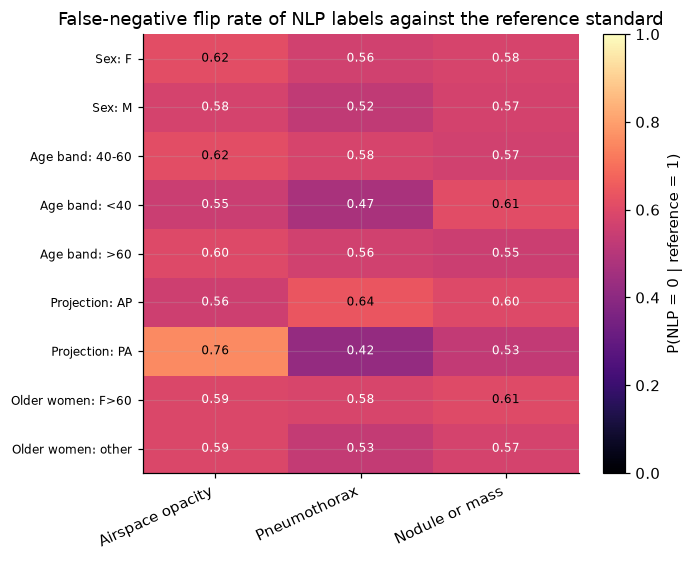

In [14]:
piv = (NOISE.assign(cell=lambda d: d["axis"].map(pc.AXIS_LABELS) + ": " + d["group"])
       .pivot_table(index="cell", columns="finding", values="eps_plus_FN", sort=False))
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(piv.values, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=25, ha="right")
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.6 else "black", fontsize=8)
ax.set_title("False-negative flip rate of NLP labels against the reference standard")
fig.colorbar(im, ax=ax, fraction=0.046, label="P(NLP = 0 | reference = 1)")
plt.savefig(CFG.fig_dir / "fig5_noise_heatmap.png", bbox_inches="tight"); plt.show()

---
## 8. Calibration against the reference standard (unchanged)

,finding,axis,group,n,ece_uniform,ece_quantile,brier
0,Airspace opacity,overall,all,4375,0.0542,0.0521,0.1731
1,Airspace opacity,sex,F,1765,0.0617,0.0593,0.1819
2,Airspace opacity,sex,M,2610,0.0542,0.0526,0.1672
6,Airspace opacity,elderly_women,F>60,361,0.0616,0.0579,0.1731
7,Airspace opacity,elderly_women,other,4014,0.0563,0.0543,0.1731
8,Pneumothorax,overall,all,4375,0.1829,0.1901,0.1508
9,Pneumothorax,sex,F,1765,0.2027,0.2098,0.1651
10,Pneumothorax,sex,M,2610,0.1695,0.1751,0.1411
14,Pneumothorax,elderly_women,F>60,361,0.1751,0.1884,0.1619
15,Pneumothorax,elderly_women,other,4014,0.1836,0.1901,0.1498


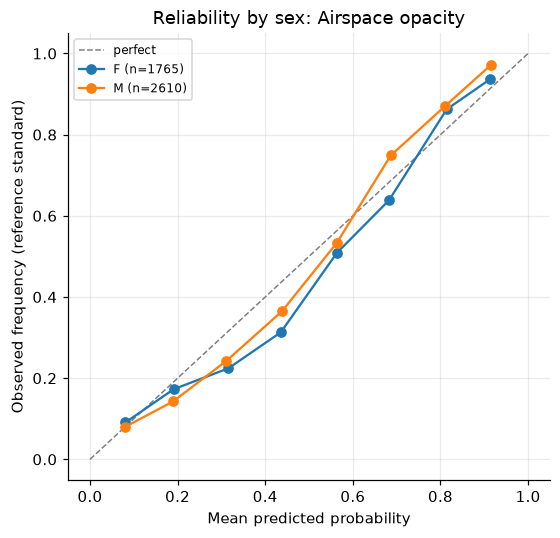

In [15]:
def calibration_table(ev, axes=("sex", "age_band", "elderly_women")):
    rows = []
    for f in NLP_FINDINGS:
        sc, ad = "score_" + f, "adj_" + f
        sub = ev[ev[ad].notna()]
        y, p = sub[ad].astype(int).values, sub[sc].values
        rows.append({"finding": f, "axis": "overall", "group": "all", "n": len(sub),
                     "ece_uniform": pc.ece(y, p, CFG.n_calib_bins, "uniform"),
                     "ece_quantile": pc.ece(y, p, CFG.n_calib_bins, "quantile"), "brier": pc.brier(y, p)})
        for ax in axes:
            for g, grp in sub.groupby(ax):
                yy, pp = grp[ad].astype(int).values, grp[sc].values
                if len(yy) < 20: continue
                rows.append({"finding": f, "axis": ax, "group": str(g), "n": len(grp),
                             "ece_uniform": pc.ece(yy, pp, CFG.n_calib_bins, "uniform"),
                             "ece_quantile": pc.ece(yy, pp, CFG.n_calib_bins, "quantile"), "brier": pc.brier(yy, pp)})
    return pd.DataFrame(rows)
CALIB = calibration_table(EVAL); CALIB.to_csv(CFG.tab_dir / "table4_calibration.csv", index=False)
display(CALIB[CALIB["axis"].isin(["overall", "sex", "elderly_women"])].round(4))

f0 = max(NLP_FINDINGS, key=lambda f: int(np.nansum(EVAL["adj_" + f].values)))
sub = EVAL[EVAL["adj_" + f0].notna()]
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="perfect")
for g, grp in sub.groupby("sex"):
    y, p = grp["adj_" + f0].astype(int).values, grp["score_" + f0].values
    edges = np.linspace(0, 1, 9); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mm = (p > lo) & (p <= hi) if lo > 0 else (p >= lo) & (p <= hi)
        if mm.sum() >= 5: xs.append(p[mm].mean()); ys.append(y[mm].mean())
    ax.plot(xs, ys, marker="o", label=f"{g} (n={len(grp)})")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed frequency (reference standard)")
ax.set_title(f"Reliability by sex: {f0}"); ax.legend(fontsize=8)
plt.savefig(CFG.fig_dir / "fig6_reliability_sex.png", bbox_inches="tight"); plt.show()

---
## 9. Subgroup discrimination with patient-level intervals

ROC and precision-recall curves by sex (unchanged), and a table of subgroup AUROCs with DeLong and patient-level bootstrap intervals.

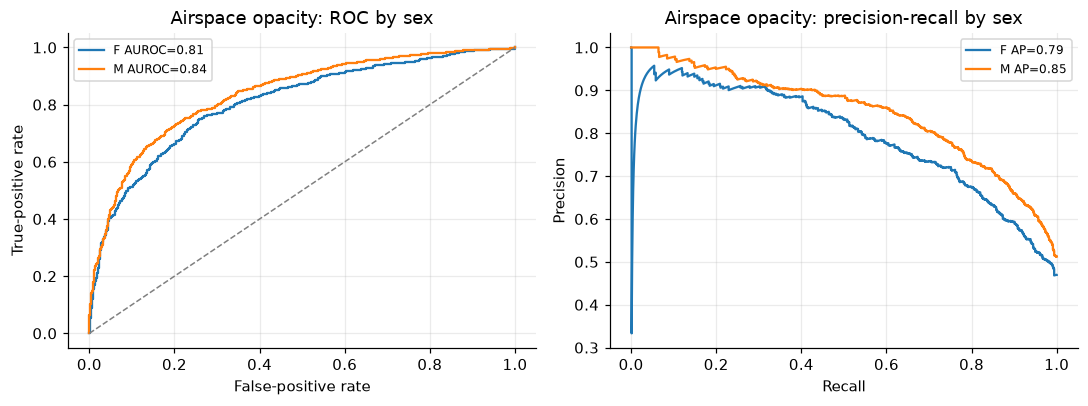

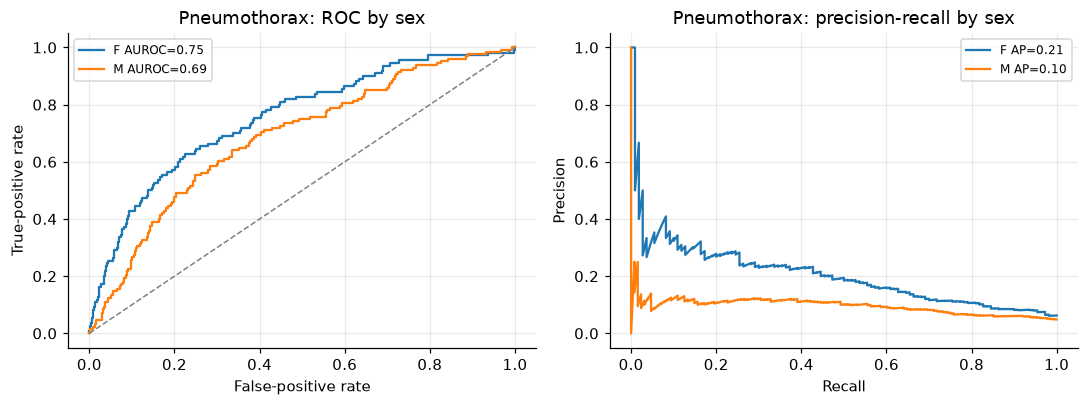

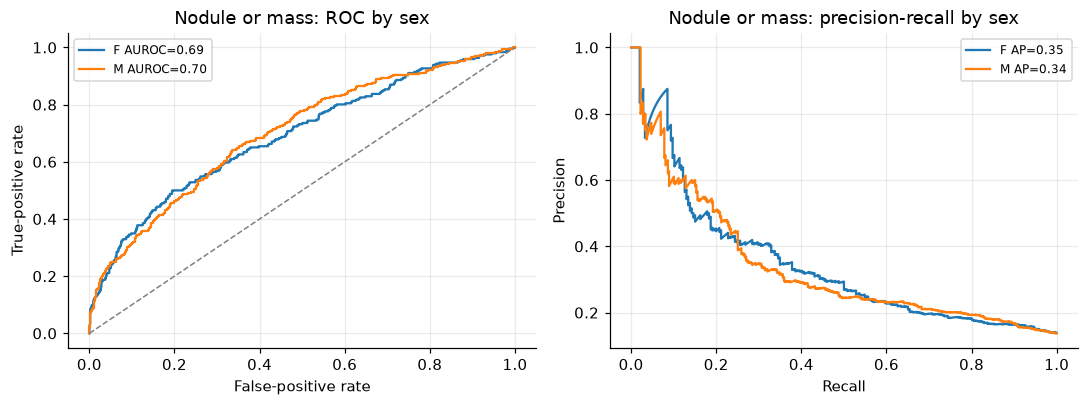

,finding,axis,group,n_images,n_patients,n_pos,auroc,delong_lo,delong_hi,patient_boot_lo,patient_boot_hi
0,Airspace opacity,overall,all,4375,1694,2166,0.826,0.813,0.838,0.808,0.842
1,Airspace opacity,sex,F,1765,724,829,0.807,0.787,0.828,0.780,0.834
2,Airspace opacity,sex,M,2610,970,1337,0.837,0.822,0.853,0.813,0.859
3,Airspace opacity,age_band,40-60,1917,711,970,0.840,0.822,0.858,0.812,0.864
4,Airspace opacity,age_band,<40,1435,568,677,0.825,0.804,0.846,0.794,0.852
5,Airspace opacity,age_band,>60,1023,452,519,0.801,0.773,0.828,0.763,0.836
6,Airspace opacity,view,AP,3244,1109,1802,0.854,0.841,0.867,0.835,0.871
7,Airspace opacity,view,PA,1131,809,364,0.680,0.646,0.714,0.643,0.715
8,Airspace opacity,elderly_women,F>60,361,163,176,0.825,0.783,0.868,0.768,0.873
9,Airspace opacity,elderly_women,other,4014,1534,1990,0.826,0.813,0.839,0.807,0.843


In [16]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
for f in NLP_FINDINGS:
    ad, sc = "adj_" + f, "score_" + f
    sub = EVAL[EVAL[ad].notna()]
    fig, axes_ = plt.subplots(1, 2, figsize=(10, 3.8))
    for g, grp in sub.groupby("sex"):
        y, p = grp[ad].astype(int).values, grp[sc].values
        if len(np.unique(y)) < 2: continue
        fpr, tpr, _ = roc_curve(y, p); axes_[0].plot(fpr, tpr, label=f"{g} AUROC={roc_auc_score(y, p):.2f}")
        pr, rc, _ = precision_recall_curve(y, p); axes_[1].plot(rc, pr, label=f"{g} AP={average_precision_score(y, p):.2f}")
    axes_[0].plot([0, 1], [0, 1], ls="--", c="grey", lw=1); axes_[0].set_title(f"{f}: ROC by sex")
    axes_[0].set_xlabel("False-positive rate"); axes_[0].set_ylabel("True-positive rate"); axes_[0].legend(fontsize=8)
    axes_[1].set_title(f"{f}: precision-recall by sex"); axes_[1].set_xlabel("Recall"); axes_[1].set_ylabel("Precision")
    axes_[1].legend(fontsize=8)
    plt.savefig(CFG.fig_dir / f"fig7_roc_pr_{f.replace(' ', '_')}.png", bbox_inches="tight"); plt.show()

with TIMES.track("subgroup_auroc_table"):
    SGAUC = pc.subgroup_auroc_table(EVAL, NLP_FINDINGS, AXES, n_boot=min(CFG.n_bootstrap, 2000), seed=CFG.random_seed,
                                    chunk=CFG.boot_chunk)
SGAUC.to_csv(CFG.tab_dir / "table_subgroup_auroc.csv", index=False)
display(SGAUC.round(3))

---
## 10. Bias amplification (unchanged)

In [17]:
def biasamp_a_to_t(g_train, a_train, ghat_test, a_test):
    g_train, a_train, ghat, a_test = map(np.asarray, (g_train, a_train, ghat_test, a_test))
    Pg, Pa = g_train.mean(), a_train.mean(); Pga = ((g_train == 1) & (a_train == 1)).mean()
    yv = 1.0 if Pga > Pg * Pa else 0.0
    if (a_test == 1).sum() == 0 or (a_train == 1).sum() == 0: return np.nan
    delta = ((ghat == 1) & (a_test == 1)).sum() / (a_test == 1).sum() - ((g_train == 1) & (a_train == 1)).sum() / (a_train == 1).sum()
    return float(yv * delta + (1 - yv) * (-delta))

rows = []
for f in NLP_FINDINGS:
    ad, sc = "adj_" + f, "score_" + f; thr = MODELS[P]["thresholds"].get(f, 0.5)
    sub = EVAL[EVAL[ad].notna()].copy(); sub["_yhat"] = (sub[sc].values >= thr).astype(int)
    for ax in ("sex", "elderly_women"):
        grps = sorted(sub[ax].unique())
        base = {g: sub[sub[ax] == g][ad].astype(int).mean() for g in grps}
        sel = {g: sub[sub[ax] == g]["_yhat"].mean() for g in grps}
        g_hi = max(base, key=base.get); gv = (sub[ax] == g_hi).astype(int).values
        rows.append({"finding": f, "axis": ax, "label_disparity": max(base.values()) - min(base.values()),
                     "prediction_disparity": max(sel.values()) - min(sel.values()),
                     "amplification": (max(sel.values()) - min(sel.values())) - (max(base.values()) - min(base.values())),
                     "biasamp_directional": biasamp_a_to_t(gv, sub[ad].astype(int).values, gv, sub["_yhat"].values)})
AMP = pd.DataFrame(rows); AMP.to_csv(CFG.tab_dir / "table5_bias_amplification.csv", index=False); display(AMP.round(3))

,finding,axis,label_disparity,prediction_disparity,amplification,biasamp_directional
0,Airspace opacity,sex,0.043,0.010,-0.032,-0.016
1,Airspace opacity,elderly_women,0.008,0.032,0.024,0.003
2,Pneumothorax,sex,0.013,0.091,0.078,-0.011
3,Pneumothorax,elderly_women,0.049,0.079,0.030,-0.056
4,Nodule or mass,sex,0.002,0.025,0.023,-0.024
5,Nodule or mass,elderly_women,0.036,0.023,-0.013,-0.014


---
## 11. Threshold sweep (unchanged)

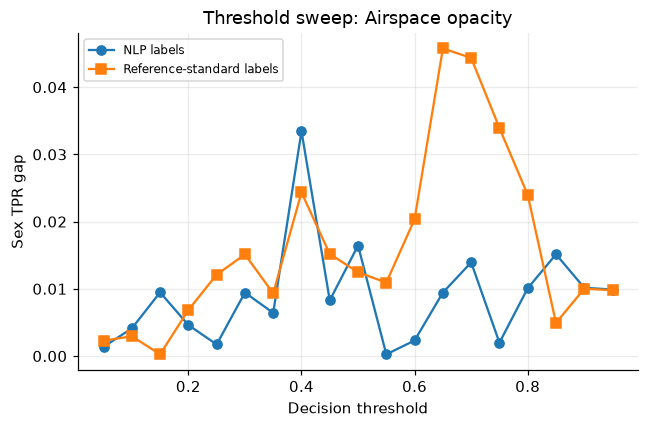

In [18]:
f0 = NLP_FINDINGS[0]; sub = EVAL[EVAL["adj_" + f0].notna()]
ts = np.linspace(0.05, 0.95, 19)
gn = [pc.gap_from_groups(pc.group_values(sub, "sex", "score_" + f0, "nlp_" + f0, t, "tpr")) for t in ts]
ga = [pc.gap_from_groups(pc.group_values(sub, "sex", "score_" + f0, "adj_" + f0, t, "tpr")) for t in ts]
pd.DataFrame({"threshold": ts, "tpr_gap_nlp": gn, "tpr_gap_ref": ga}).to_csv(CFG.tab_dir / "table_threshold_sweep.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ts, gn, marker="o", label="NLP labels"); ax.plot(ts, ga, marker="s", label="Reference-standard labels")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Sex TPR gap"); ax.set_title(f"Threshold sweep: {f0}"); ax.legend(fontsize=8)
plt.savefig(CFG.fig_dir / "fig8_threshold_sweep.png", bbox_inches="tight"); plt.show()

---
## 12. Backbone comparison, including a backbone never exposed to NIH data

The regime-difference family is repeated for every backbone with patient-level intervals. The CheXpert-only DenseNet-121 is new: it is domain-specific like the primary backbone but was trained only on CheXpert, so it never saw NIH images, NIH NLP labels or the adjudicated labels. **Its embeddings are extracted the first time this cell runs (roughly 3 to 4 hours on a laptop CPU for train, validation and evaluation; cached afterwards).** Set `CFG.chex_full_pipeline = False` to skip it here; Part 4 then still uses its native outputs on the evaluation set (about 25 minutes).

In [19]:
ABL = []
for bb in CFG.embedding_backbones:
    if bb == "xrv_densenet121_chex" and not CFG.chex_full_pipeline:
        print("Skipping CheXpert-only backbone (CFG.chex_full_pipeline = False)."); continue
    try:
        if bb not in EMB:
            with TIMES.track(f"embeddings_{bb}"):
                EMB[bb] = pc.embed_frames(CFG, bb, FRAMES)
        if EMB[bb]["train"][0] is None:
            print(f"{bb}: embeddings unavailable, skipped."); continue
        if bb not in MODELS:
            HEAD_TIMES[bb] = {}
            MODELS[bb] = pc.train_heads(EMB[bb], NLP_FINDINGS, C=CFG.head_C, timings=HEAD_TIMES[bb])
            pc.write_json(CFG.prov_dir / f"head_timings_{bb}.json", HEAD_TIMES[bb])
        EVALS[bb] = pc.filter_eval_groups(pc.build_eval_scores(MODELS[bb], bb), AXES, CFG.min_group_n)
        with TIMES.track(f"regime_table_{bb}"):
            t = pc.regime_difference_table(EVALS[bb], NLP_FINDINGS, AXES, MODELS[bb]["thresholds"], n_boot=CFG.n_bootstrap,
                                           seed=CFG.random_seed, chunk=CFG.boot_chunk, levels=("patient",))
        t.insert(0, "backbone", bb); t.insert(1, "exposure", pc.BACKBONE_EXPOSURE[bb]["status"]); ABL.append(t)
    except RuntimeError:
        raise
    except Exception as e:
        log.warning("Backbone %s failed: %s", bb, e)
if ABL:
    ABL = pd.concat(ABL, ignore_index=True)
    ABL.to_csv(CFG.tab_dir / "table6_backbone_ablation.csv", index=False)
    key = ABL[(ABL["metric"] == "tpr") & ABL["axis"].isin(["sex", "elderly_women"])]
    display(key[["backbone", "finding", "axis", "regime_diff", "diff_lo_patient", "diff_hi_patient", "p_two_patient"]].round(3))
    summ = ABL.groupby("backbone").apply(lambda d: pd.Series({
        "positive_all24": int((d["regime_diff"] > 0).sum()),
        "median_diff_all24": d["regime_diff"].median(),
        "positive_tpr_sex_olderwomen": int(((d["metric"] == "tpr") & d["axis"].isin(["sex", "elderly_women"]) & (d["regime_diff"] > 0)).sum()),
        "intervals_excluding_zero": int(((d["diff_lo_patient"] > 0) | (d["diff_hi_patient"] < 0)).sum())}), include_groups=False)
    summ.to_csv(CFG.tab_dir / "table6_backbone_summary.csv"); display(summ)

Skipping CheXpert-only backbone (CFG.chex_full_pipeline = False).


,backbone,finding,axis,regime_diff,diff_lo_patient,diff_hi_patient,p_two_patient
0,xrv_densenet121,Airspace opacity,sex,-0.010,-0.052,0.032,0.745
6,xrv_densenet121,Airspace opacity,elderly_women,-0.039,-0.116,0.066,0.566
8,xrv_densenet121,Pneumothorax,sex,0.002,-0.120,0.125,0.991
14,xrv_densenet121,Pneumothorax,elderly_women,0.120,-0.074,0.235,0.265
16,xrv_densenet121,Nodule or mass,sex,-0.046,-0.117,0.077,0.664
22,xrv_densenet121,Nodule or mass,elderly_women,0.049,-0.121,0.206,0.588
24,resnet50_imagenet,Airspace opacity,sex,0.018,-0.034,0.059,0.596
30,resnet50_imagenet,Airspace opacity,elderly_women,-0.017,-0.101,0.052,0.726
32,resnet50_imagenet,Pneumothorax,sex,0.023,-0.113,0.157,0.757
38,resnet50_imagenet,Pneumothorax,elderly_women,0.065,-0.138,0.230,0.585


,positive_all24,median_diff_all24,positive_tpr_sex_olderwomen,intervals_excluding_zero
backbone,,,,
clip_vitb32,16.0,0.012714,3.0,0.0
resnet50_imagenet,18.0,0.015788,5.0,2.0
xrv_densenet121,16.0,0.021352,3.0,1.0


---
## 13. Fracture: the limiting case

ChestX-ray14 has no fracture label, so an NLP-label audit sees no fracture disparity at all. **13a** reproduces the original analysis (primary backbone's native fracture output, threshold by Youden's index on the evaluation labels). Note that the primary backbone's training data included the adjudicated NIH labels, fracture among them, so its fracture scores are exposed to the very labels they are tested against. **13b** therefore repeats the analysis with the CheXpert-only backbone's native fracture output, reports threshold-free AUROC gaps with patient-level intervals, and chooses the TPR threshold on one random half of the patients and measures the gap on the other half (25 repetitions), so no threshold is tuned on its own test labels.

In [20]:
# 13a. Original analysis (exposed backbone; threshold chosen on the evaluation labels; descriptive)
def compute_xrv_native(frame, pathology="Fracture"):
    cache = CFG.emb_dir / f"evalclean__xrvnative_{pathology}.npy"; idxp = CFG.emb_dir / f"evalclean__xrvnative_{pathology}__index.parquet"
    ids = frame["Image Index"].astype(str).tolist()
    if cache.exists() and idxp.exists() and pd.read_parquet(idxp)["Image Index"].tolist() == ids:
        return np.load(cache)
    if "image_path" not in frame.columns: return None
    bb = pc.build_backbone("xrv_densenet121")
    if bb is None: return None
    import torch as T
    from PIL import Image
    model = bb.model; pidx = model.pathologies.index(pathology); out, buf = [], []
    def flush():
        if not buf: return
        with T.no_grad(): out.append(model(T.stack(buf, 0))[:, pidx].cpu().numpy())
        buf.clear()
    for pth in frame["image_path"].tolist():
        try: img = Image.open(pth).convert("L")
        except Exception: img = Image.new("L", (224, 224))
        buf.append(bb.preprocess(img))
        if len(buf) >= CFG.embed_batch_size: flush()
    flush(); arr = np.concatenate(out)
    np.save(cache, arr); pd.DataFrame({"Image Index": ids}).to_parquet(idxp, index=False)
    return arr

fr_eval = eval_clean[eval_clean["adj_Fracture"].notna()].copy()
xrv_frac = compute_xrv_native(fr_eval)
FRAC_ROWS = []
if xrv_frac is not None:
    fr_eval["xrv_Fracture"] = xrv_frac
    thr_f = pc.youden_threshold(fr_eval["adj_Fracture"].astype(int).values, xrv_frac)
    for ax in ["sex", "age_band", "elderly_women"]:
        prev = {g: fr_eval[fr_eval[ax] == g]["adj_Fracture"].astype(int).mean() for g in fr_eval[ax].unique()}
        FRAC_ROWS.append({"axis": ax, "nlp_regime_gap": 0.0,
                          "clean_auroc_gap": pc.gap_from_groups(pc.group_values(fr_eval, ax, "xrv_Fracture", "adj_Fracture", thr_f, "auroc")),
                          "clean_tpr_gap": pc.gap_from_groups(pc.group_values(fr_eval, ax, "xrv_Fracture", "adj_Fracture", thr_f, "tpr")),
                          "adj_prevalence_gap": max(prev.values()) - min(prev.values())})
    pd.DataFrame(FRAC_ROWS).to_csv(CFG.tab_dir / "table7_fracture_case.csv", index=False)
    display(pd.DataFrame(FRAC_ROWS).round(3))
else:
    print("Native fracture scores of the primary backbone unavailable (no cache and no images).")

,axis,nlp_regime_gap,clean_auroc_gap,clean_tpr_gap,adj_prevalence_gap
0,sex,0.0,0.040,0.047,0.030
1,age_band,0.0,0.087,0.248,0.061
2,elderly_women,0.0,0.075,0.038,0.022


In [21]:
# 13b. Unexposed backbone, patient-level AUROC intervals, cross-fitted TPR thresholds
FR = EVAL[["Image Index", "patient_id", "adj_Fracture"] + AXES].copy()
SCORERS = {}
if xrv_frac is not None:
    SCORERS["xrv_densenet121 (exposed)"] = pd.Series(xrv_frac, index=fr_eval.index).reindex(FR.index).values
nat, paths_ = pc.get_native_scores(CFG, "evalclean", eval_clean, "xrv_densenet121_chex")
if nat is not None:
    SCORERS["xrv_densenet121_chex (not exposed)"] = nat[FR.index.values, paths_.index("Fracture")]
rows = []
for name, s in SCORERS.items():
    FR["_s"] = s
    y = FR["adj_Fracture"].astype(int).values
    overall = pc.auc_ci_delong(y, s)
    for ax in ["sex", "age_band", "elderly_women"]:
        eng = pc.GapEngine(FR[ax].values, s, 0.5, {"adj": y})
        codes, nc = pc.encode_clusters(FR["patient_id"].values)
        G = np.concatenate([eng.gaps(W, "adj", "auroc") for W in pc.iter_boot_weights(codes, nc, CFG.n_bootstrap, CFG.random_seed, CFG.boot_chunk)])
        auc_gap = float(eng.gaps(np.ones((1, len(FR))), "adj", "auroc")[0])
        thr_full = pc.youden_threshold(y, s)
        tpr_full = pc.gap_from_groups(pc.group_values(FR, ax, "_s", "adj_Fracture", thr_full, "tpr"))
        xs = []
        pats = FR["patient_id"].unique()
        for rep in range(25):
            r = np.random.default_rng(CFG.random_seed + rep); pp = pats.copy(); r.shuffle(pp)
            A = FR["patient_id"].isin(set(pp[: len(pp) // 2])).values
            tA = pc.youden_threshold(y[A], s[A])
            xs.append(pc.gap_from_groups(pc.group_values(FR[~A], ax, "_s", "adj_Fracture", tA, "tpr")))
        rows.append({"scorer": name, "overall_auroc": overall[0], "overall_auroc_lo": overall[1], "overall_auroc_hi": overall[2],
                     "axis": ax, "auroc_gap": auc_gap, "auroc_gap_lo_patient": pc._pct(G, 2.5),
                     "auroc_gap_hi_patient": pc._pct(G, 97.5), "tpr_gap_threshold_on_eval_labels": tpr_full,
                     "tpr_gap_crossfit_mean": np.nanmean(xs), "tpr_gap_crossfit_p2.5": np.nanpercentile(xs, 2.5),
                     "tpr_gap_crossfit_p97.5": np.nanpercentile(xs, 97.5), "nlp_audit_gap": 0.0})
FRAC2 = pd.DataFrame(rows)
FRAC2.to_csv(CFG.tab_dir / "table7b_fracture_unexposed_crossfit.csv", index=False)
display(FRAC2.round(3))

18:02:48 [INFO] Backbone ready: xrv_densenet121_chex


,scorer,overall_auroc,overall_auroc_lo,overall_auroc_hi,axis,auroc_gap,auroc_gap_lo_patient,auroc_gap_hi_patient,tpr_gap_threshold_on_eval_labels,tpr_gap_crossfit_mean,tpr_gap_crossfit_p2.5,tpr_gap_crossfit_p97.5,nlp_audit_gap
0,xrv_densenet121 (exposed),0.547,0.507,0.587,sex,0.040,0.003,0.152,0.047,0.077,0.009,0.208,0.0
1,xrv_densenet121 (exposed),0.547,0.507,0.587,age_band,0.087,0.024,0.202,0.248,0.325,0.088,0.528,0.0
2,xrv_densenet121 (exposed),0.547,0.507,0.587,elderly_women,0.075,0.004,0.332,0.038,0.162,0.005,0.525,0.0
3,xrv_densenet121_chex (not exposed),0.605,0.563,0.647,sex,0.097,0.006,0.211,0.188,0.179,0.008,0.410,0.0
4,xrv_densenet121_chex (not exposed),0.605,0.563,0.647,age_band,0.200,0.040,0.323,0.252,0.204,0.049,0.416,0.0
5,xrv_densenet121_chex (not exposed),0.605,0.563,0.647,elderly_women,0.206,0.015,0.427,0.351,0.296,0.052,0.551,0.0


---
## 14. Provenance

In [22]:
tabs = sorted(p.name for p in CFG.tab_dir.glob("*.csv"))
prov2 = {"created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "part": "2 (revision 2)",
         "primary_backbone": P, "backbones_run": list(MODELS.keys()),
         "cohort": {"train": len(train_df), "val": len(val_df), "held_out": len(test_df), "eval": len(eval_clean),
                    "eval_patients": int(eval_clean["patient_id"].nunique())},
         "cohort_hash_check": CHECK.to_dict(orient="records") if len(CHECK) else [],
         "n_bootstrap": CFG.n_bootstrap, "bootstrap_unit": "patient (primary); image (comparison)",
         "seed": CFG.random_seed, "versions": VERSIONS, "hardware": pc.hardware_info(),
         "tables": {t: pc.sha256_file(CFG.tab_dir / t) for t in tabs}}
pc.write_json(CFG.prov_dir / "provenance_part2.json", prov2)
print("Wrote provenance_part2.json with", len(prov2["tables"]), "hashed tables")

Wrote provenance_part2.json with 29 hashed tables


---
## 15. What Part 2 now shows, and what Part 3 does

The printed summaries above are the numbers to carry into the manuscript; nothing here is hard-coded. Read the regime-difference family as descriptive: with patient-level resampling its intervals are wider than the image-level intervals of the submission, and the comparison table states for each row whether the direction changed. Part 3 tests instance dependence with cluster-aware methods across all four backbones and propagates the uncertainty of the estimated flip rates through the injection experiment. Part 4 adds the analyses requested in review that do not belong to the original pipeline.